# The intruder papers in this repo — implementation, faithfulness, adjudication

**Focus.** The two published neighbors that attribute LoRA forgetting to *intruder
dimensions*: the origin of the concept, Shuttleworth et al., *LoRA vs Full Fine-Tuning:
An Illusion of Equivalence* (arXiv:2410.21228), and its quantitative sharpening, *The
Intruder Threshold: A Spectral Law for LoRA Fine-Tuning* (arXiv:2607.23711). This
notebook is the single place that (1) states what each paper claims, (2) documents how
each is implemented here and how faithful that implementation is, and (3) recomputes
every agreement/disagreement from durable artifacts. Nothing on our side is pasted in —
every number for our populations is computed from `outputs/analysis/` artifacts in this
notebook. Threshold-paper numbers were verified against the arXiv HTML on 2026-08-28;
the Shuttleworth Fig. 8 paragraph adjudicated in §8 is quoted verbatim from the PDF.

**Our implementation surface.** Estimator `analysis/intruder_threshold.py` (clean-room:
the paper has no public code); observational scan `scripts/intruder_threshold_scan.py`
→ `intruder_threshold_strip_ds1base.csv` (1,602 strip runs); causal probes
`scripts/three_shape_surgery.py`, `scripts/diffuse_ladder_surgery.py` (matched-F and
matched-σ), `scripts/trained_direction_ladder.py`, and the intruder pass of
`scripts/position_surgery.py`. Prose companions: `collapse_program_synthesis.md` §5b,
`collapse_claims_v2.md` N9.

**Conventions.** Dead = the OPERATIVE anchored cut, drift > Δ_cross(receiver) =
H_uni − ce_base (`probe_io.anchored_dead_cut`); the declared KL > 4.0 is the standing
comparison cut — fate tables below quote both, anchored first. ΔCE is the
display-primary drift readout where the artifact carries it (`*_ce*` files, ce-wave
08-27); `three_shape_surgery_ds1.json` is KL-era only (its KL-era counterparts agree with
ΔCE within 0.3 nat). Dose dw_fro = mean over LoRA modules of (α/r)·‖BA‖_F/‖W₀‖_F.
Row units, selections, and aggregations are stated at each table.

**Sections.** §0b the populations under study · §1 what the threshold paper claims ·
§2 faithfulness audit (component by component) + live estimator verification ·
§3 observational head-to-head (their s\* statistics vs our dose, 1,602 runs) · §4 direction injection,
the {k=1,16} × {random, W₀-aligned} corners (their shapes + our behavioral readout) ·
§5 direction injection, concentration sweeps (total-size-matched; strength-matched control) ·
§6 direction injection, trained-update-aligned source · §7 the direction surgery's intruder pass (real updates) ·
§8 Shuttleworth et al.: faithfulness + the Fig. 8 paragraph adjudicated · §9 verdict.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

from subliminal_learning.config import resolve_roots
from subliminal_learning.analysis.setup import set_plot_style
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis.stats import mannwhitney_auc
from subliminal_learning.analysis.intruder_threshold import (
    EPS_CENTRAL, EPS_GRID, bulk_edge, theta_bar)
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT, anchored_dead_cut

set_plot_style()
OUT, _ = resolve_roots(None, None)
A = OUT / 'analysis'
DC_DS1 = anchored_dead_cut(OUT, 'pythia-160m-data-seed1')

def read_jsonl(p):
    return pd.DataFrame([json.loads(l) for l in Path(p).read_text().splitlines() if l.strip()])

def intr_frac(s):
    '''"41/48" -> 41/48 as float.'''
    a, b = s.split('/')
    return int(a) / int(b)

def auc_with_inf(scores, dead):
    '''Mann-Whitney AUC, retaining +/-inf scores (diverged runs) by clipping them just
    past the finite range so their ordering survives (mannwhitney_auc drops non-finite).'''
    s = np.asarray(scores, dtype=float)
    fin = s[np.isfinite(s)]
    s = np.clip(s, fin.min() - 1.0, fin.max() + 1.0)
    d = np.asarray(dead, dtype=bool)
    return mannwhitney_auc(s[d], s[~d])

print(f'output_root = {OUT}')
print(f'anchored cut (ds1 receiver) Delta_cross = {DC_DS1:.3f} nats; comparison cut = {DEAD_KL_CUT}')

output_root = /mnt/cold-1/soar-subliminal/angela/outputs
anchored cut (ds1 receiver) Delta_cross = 5.123 nats; comparison cut = 4.0


## §0b The populations under study

Everything in this notebook lives on the **dog | orig-teacher lineage of the 160m
family**: numbers generated by the selected orig teacher (pythia-160m,
`ep2_lr5e-4_r32a64` ftseed1, `ex10-20_prefix` pools at n100k), distilled into two
receivers — **ds1** (`pythia-160m-data-seed1`; the strip and trait-free arms) and
**orig** (`pythia-160m`; the same-model arm) — plus the **teacher-FT runs themselves**
(the teacher arm). The direction injections go into the *bare bases* (no trained run
involved; ds1, with the total-size-matched sweep replicated on orig), and the
trained-update-aligned source borrows its directions from two r128 strip runs. The cell below computes the
inventory from the artifacts themselves — run counts, receiver bases, and the common
run-tree prefix per arm — so this table can never drift from the records.

In [2]:
# Row unit: one experiment family; runs = distinct run directories in that artifact.
import os
def arm_row(name, path):
    df = read_jsonl(A / path)
    pref = os.path.commonprefix(sorted(df.run.unique()))
    pref = pref[len(str(OUT)) + 1:] if pref.startswith(str(OUT)) else pref
    return dict(family=name, runs=df.run.nunique(),
                receiver=', '.join(sorted(b.split('/')[-1] for b in df.base.unique())),
                common_tree=pref)
inv = pd.DataFrame([
    arm_row('surgery: strip arm (ftseeds 1+2)', 'position_surgery_ce_strip.jsonl'),
    arm_row('surgery: same-model arm', 'position_surgery_ce_samemodel.jsonl'),
    arm_row('surgery: teacher arm', 'position_surgery_ce_teacher.jsonl'),
    arm_row('surgery: trait-free arm', 'position_surgery_ce_traitfree.jsonl'),
    arm_row('surgery: rotation progression', 'position_surgery_ce_prog.jsonl'),
    arm_row('surgery: intruder pass', 'position_surgery_v2_intr.jsonl'),
])
print(inv.to_string(index=False))
n_total = inv.runs[:4].sum()
print(f"\nsurgery campaign total (four arms): {n_total} runs "
      f"(progression + intruder pass are strip subsets, not additional runs)")

scan0 = pd.read_csv(A / 'intruder_threshold_strip_ds1base.csv')
fts = scan0.leaf.str.extract(r'ftseed(\d+)')[0].value_counts().sort_index()
print(f"\nobservational scan: {len(scan0)} runs over "
      f"{scan0.leaf.str.split('/').str[0].nunique()} (lr, alpha, rank) cells of the "
      f"ds1-receiver strip (ep20 grid + boundary refinements);\n  ftseed counts: "
      + ', '.join(f'{k}: {v}' for k, v in fts.items()))

for n, lbl in [('three_shape_surgery_ds1.json', 'injection corners (legacy three-shape)'),
               ('diffuse_ladder_surgery_ds1_ce.json', 'concentration sweep, total-size-matched'),
               ('diffuse_ladder_surgery_orig_ce.json', 'concentration sweep, total-size-matched (orig replication)'),
               ('specmatch_ladder_surgery_ds1_ce.json', 'strength-matched control')]:
    print(f"injection [{lbl}]: into base {json.loads((A / n).read_text())['repo']}")
tdj = json.loads((A / 'trained_direction_ladder_ds1_ce.json').read_text())
for who in ('donor_dead', 'donor_alive'):
    print(f"trained-update-aligned {who}: .../" + '/'.join(tdj[who].split('/')[-2:]))

                          family  runs               receiver                                                                                                   common_tree
surgery: strip arm (ftseeds 1+2)    88 pythia-160m-data-seed1 students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k/ep20_lr
         surgery: same-model arm    24            pythia-160m                 students/dog/pythia-160m/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k/ep
            surgery: teacher arm    22            pythia-160m                                                                                   teachers/dog/pythia-160m/ep
         surgery: trait-free arm    24 pythia-160m-data-seed1                students/controls/base/pythia-160m-data-seed1/teacher-pythia-160m/ex10-20_prefix_n100k/ep20_lr
   surgery: rotation progression    12 pythia-160m-data-seed1 students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tsee

## §1 What the prior work claims (verified against the arXiv HTML, 2026-08-28)

**The estimator.** From the *pretrained* matrix W's empirical spectrum alone, via the
rectangular spiked-deformation (Benaych-Georges/Nadakuditi) transform:
φ(z) = (1/p)·Σᵢ z/(z²−σᵢ²) with p = min(n,m); D(z) = φ(z)·[c·φ(z) + (1−c)/z] with
c = p/max(n,m); **θ̄ = D(z₀)^(−1/2)** at z₀ = edge·(1+ε), ε pre-specified in
[10⁻⁴, 3×10⁻²]. Two edge variants: *full* (edge = σ₁(W), primary) and *bulk* (edge =
top of the bulk after a gap-test trim of isolated outliers — **their exact trim rule is
not printed in the HTML**). Degeneracy gate: the ε-sensitivity ratio R = max_ε θ̄ / min_ε θ̄;
the prediction is declared degenerate when the median R across layers exceeds 10
(their observed medians: 2.2–2.4 causal dense, 3.4–4.3 MoE/enc-dec).

**The law.** Per-layer critical update strength **s\* = θ̄/(γ·σ₁(BA))**, γ = α/r
(α/√r for rsLoRA): below s\* no intruder dimensions; above it a new singular direction
pops out of the updated spectrum. Empirical intruder detection (Shuttleworth-style): a
layer contains an intruder iff any of the **top-10** singular vectors of W + γBA has
max |overlap| < **τ = 0.5** with *every* pretrained singular vector (τ-sensitivity
stored at 0.3/0.7); per-layer binary.

**Terminology note (checked against their HTML, 08-28).** The paper's named objects
are the critical update strength **s\*** and layers **"supercritical"** (s\* < 1 at
deployment) / **"subcritical"**; the deployment-scale analysis is their "layer-level
classification of deployment risk." The word **"margin" never appears in the paper** —
it is this repo's shorthand for the reciprocal γσ₁(BA)/θ̄ = 1/s\* (>1 ⟺ supercritical),
retained in code and CSV column names (`*logmargin*`) for artifact stability. Prose in
this notebook uses their terms.

**Their evidence** (7 models: Qwen2.5-7B, Llama-3.1-8B, Mistral-7B-v0.3, OLMo-2-7B;
extension Mamba-2.8b, OLMoE-1B-7B, FLAN-T5-XL; 18 adapters, 9,840 layer scans):
threshold localization hit@2× = 82.2% [78.5, 86.2]; per-adapter rank correlation of
predicted vs empirical threshold pooled ρ = 0.661 [0.583, 0.736] (per-adapter 0.33–0.99);
deployment AUC 0.89 — note the task: separating intruder-*bearing* from intruder-*free
layers* at s = 1, not run fate. Forgetting readout: WikiText-2 perplexity, "knee" = first
strength at which PPL exceeds 1.5× base (a declared cut); the knee sits at 0.8–2.3× the
median intruder threshold (median 1.4×), ρ = 0.86 (n = 16) — "intruders appear first,
and measurable retention loss follows within a factor of about two in strength."

**Their causal claims, in their words**: "causal intervention on intruder singular
values restores pretraining behavior, **so intruders cause forgetting**" and
"**threshold-crossing layers, rather than update magnitude, carry the forgetting**"
(scaling only predicted supercritical layers vs only subcritical ones at matched total
injected Frobenius norm: WikiText-2 PPL 4.9 → 9,340 vs → 39 on Mistral r256 — a ~240×
layer asymmetry). A spike-budget rule reduces forgetting 62%.

**Their synthetic surgery** (the template for ours): four equal-norm shapes at
‖Δ‖_F = 2θ̄ per layer — {concentrated, diffuse r=16 at θ/√r per direction} ×
{generic random, top-aligned} — measuring **only whether intruders form**: generic
concentrated pops at median s = 0.5·2θ̄, diffuse-generic ~3× later, aligned never.
**They do not measure behavioral damage per shape** — that readout is this repo's
addition (§4), and it is where the mechanism claim comes apart.

## §2 Faithfulness audit — the threshold paper, component by component

| Component | Theirs (HTML) | Ours | Verdict |
|---|---|---|---|
| φ, D-transform, θ̄ | φ(z)=(1/p)Σ z/(z²−σᵢ²); D(z)=φ(z)[cφ(z)+(1−c)/z]; θ̄=D(z₀)^(−1/2), z₀=edge(1+ε), ε∈[1e-4,3e-2] | identical formulas (`intruder_threshold.py`), ε grid = their range, central ε=3e-3; float64 | **Faithful** (clean-room; no public code to diff against) |
| Edge variants | full (primary) + bulk after a gap-test trim; **trim rule not printed** | both edges; our documented trim: drop leading σ's whose gap > 10× the median top-spectrum spacing | Faithful in design; **trim rule is ours** |
| Degeneracy gate | median R > 10 ⇒ degenerate | same grid, same ratio; our per-module median printed below | Faithful; our R ≈ 4.6 passes but sits above their causal-dense 2.2–2.4 |
| LoRA scale | γ = α/r; rsLoRA α/√r noted | γ = α/r; the scan **raises** on rsLoRA adapters rather than silently mis-scaling | Faithful |
| σ₁(BA) | (not specified) | exact via QR trick, σ(BA) = σ(R_B·A), no n×m product | Exact — no approximation to be unfaithful about |
| Intruder detection | top-10 singular vectors of W+γBA, max abs overlap vs ALL pretrained < τ=0.5, per-layer binary; τ-sensitivity {0.3, 0.7} | identical criterion and constants (`empirical_intruders` tau=0.5, top_k=10); surgery scripts check the **left** side only (their side is unstated; `empirical_intruders` returns both); per-module binary, same | **Faithful**; τ-sensitivity not re-run here |
| Counting scope | all layers | all 48 modules in the ladders + surgery intruder pass; stride-6 spot-checks (8/48) in `three_shape_surgery` and `trained_direction_ladder` | Partial deviation, documented per artifact |
| Forgetting readout | WikiText-2 PPL; knee = first strength with PPL > 1.5× base (declared cut, no external anchor) | the held-out Pile probe (32×512 val docs; internal tag `pp1`), ΔCE/KL vs own base; dead = the unigram-anchored cut (absolute semantic bar), KL>4 as comparison | **Deliberate departure.** Pile *is* Pythia's pretraining distribution, so it is the right forgetting corpus here; both labels binarize a continuous drift, ours carries an external anchor |
| Threshold object | per-layer s\*, ranked within adapter; deployment AUC = layer-level intruder-bearing vs -free | per-run aggregates for fate: frac_super (full/bulk), med/max log(1/s\*) (columns keep the repo shorthand 'margin') | **Our aggregation** — required to score a run-level outcome; several aggregates tried, each reported (§3). Their 0.89 and our ~0.98 are different tasks — never compare them head-to-head |
| Models | 7B-class ×7 | Pythia-160m bases (ds1 spectra; orig-spectra rerun agreed ≤0.01 AUC) | Scale transfer justified by **their own** ε-gate passing here |
| Causal test | shrink intruder σ's (restores behavior); layer-scaling at matched total norm | **neither run verbatim.** Our interventions are spectrum-preserving rotations/injections — sharper on direction identity (their shrink removes energy *and* direction together), silent on their layer-allocation claim | Departure by design; their two interventions remain unreplicated here |

Net: the *instrument* is a faithful clean-room implementation (recipe, constants, gates,
detection criterion all match the HTML), with three honest deviations — our bulk-trim
rule, spot-check striding in two scripts, and left-side-only counting in the surgery
scripts — none of which touches a load-bearing number (the ladders and the surgery pass
use all-48 counts; full-edge margins drive the §3 AUCs). The *evaluation* is deliberately
not theirs: our corpus, drift readout, dead label, and run-level aggregation. The cell
below live-verifies the estimator-level claims.

In [3]:
# §2b Estimator verification on the ds1 base spectra (the scan's own cache).
# Row unit: LoRA-target module (48 = 12 layers x 4 projections); columns are medians
# over modules of that type; 'all' = median over all 48.
z = np.load(A / 'intruder_threshold_strip_ds1base.base_spectra.npz', allow_pickle=True)
spectra = {k: tuple(v) for k, v in z['spectra'].item().items()}
rows = []
for key, (sig, shape, w_fro) in spectra.items():
    th_full = theta_bar(sig, shape, EPS_CENTRAL, 'full')
    thetas = [theta_bar(sig, shape, e, 'full') for e in EPS_GRID]
    rows.append(dict(
        module=key, mtype='.'.join(key.split('.')[2:]),
        theta_full=th_full, theta_bulk=theta_bar(sig, shape, EPS_CENTRAL, 'bulk'),
        theta_over_wfro=th_full / w_fro, theta_over_sigma1=th_full / float(np.max(sig)),
        eps_ratio=max(thetas) / min(thetas)))
est = pd.DataFrame(rows)
cols = ['theta_full', 'theta_bulk', 'theta_over_wfro', 'theta_over_sigma1', 'eps_ratio']
tab = est.groupby('mtype')[cols].median()
tab.loc['ALL (median over 48 modules)'] = est[cols].median()
print(tab.round(4).to_string())
print(f"\nGate: median eps-sensitivity ratio R = {est.eps_ratio.median():.2f} "
      f"(their degeneracy bar: 10; their causal-dense medians 2.2-2.4)")
print(f"Scale bridge: median theta_bar/||W0||_F = {est.theta_over_wfro.median():.3f} "
      f"vs the trained-update Frobenius thresholds theta-hat ~ 0.13-0.14 (strip, N3)")
print(f"A direction must reach ~{est.theta_over_sigma1.median():.2f} x sigma1(W0) to pop out.")

                              theta_full  theta_bulk  theta_over_wfro  theta_over_sigma1  eps_ratio
mtype                                                                                              
attention.dense                   1.6560      0.9632           0.1207             0.7795     7.1935
attention.query_key_value        19.4749      3.1467           0.4148             0.8755     4.9418
mlp.dense_4h_to_h                 4.0188      2.1670           0.1114             0.8454     4.3413
mlp.dense_h_to_4h                 5.3592      2.6805           0.1236             0.8552     4.3798
ALL (median over 48 modules)      5.0217      2.4501           0.1236             0.8517     4.6353

Gate: median eps-sensitivity ratio R = 4.64 (their degeneracy bar: 10; their causal-dense medians 2.2-2.4)
Scale bridge: median theta_bar/||W0||_F = 0.124 vs the trained-update Frobenius thresholds theta-hat ~ 0.13-0.14 (strip, N3)
A direction must reach ~0.85 x sigma1(W0) to pop out.


## §3 Observational head-to-head: their critical-strength statistics vs our dose as fate coordinates

Row unit: strip run (ep20 grid, orig→ds1 receiver; n = 1,602 incl. 76 diverged).
Scores: their per-run aggregates (fraction of supercritical modules, median/max
log(1/s\*), both edges — the supercriticality aggregates) vs our dw_fro, dw_spec, and the boundary coordinate
K = lr·α^b·r^c at the settled exponents. Label: dead = ΔCE > cut (anchored ds1 first,
comparison KL 4.0 second); diverged runs (ΔCE = ∞) are dead with scores clipped just past
the finite range (ordering preserved). AUC = Mann-Whitney P(dead > alive). The two
stratified rows at the bottom ask the residual-information question both ways: the AUC
of one score *within deciles* of the other (weighted over mixed-fate strata) — 0.5
means the score adds nothing once the other is known, below 0.5 means it orders fate
*backwards* within strata. Few strata are mixed-fate (the boundary band), so read these
two numbers qualitatively — the asymmetry, not the third decimal.

In [4]:
scan = pd.read_csv(A / 'intruder_threshold_strip_ds1base.csv')
scan['K'] = cl.K_of(scan.lr, scan.alpha, scan['rank'])
SCORES = ['frac_super_full', 'frac_super_bulk', 'med_logmargin_full',
          'max_logmargin_full', 'med_logmargin_bulk', 'dw_fro', 'dw_spec', 'K']
res = {}
for cut, name in [(DC_DS1, f'AUC (anchored {DC_DS1:.2f})'), (DEAD_KL_CUT, 'AUC (KL>4)')]:
    dead = scan.delta_ce > cut
    res[name] = {s: auc_with_inf(scan[s], dead) for s in SCORES}
auc_tab = pd.DataFrame(res).sort_values(list(res)[0], ascending=False)
print(auc_tab.round(3).to_string())

fin = scan[np.isfinite(scan.dw_fro) & np.isfinite(scan.frac_super_full)]
print(f"\ncorr(log dw_fro, frac_super_full) = "
      f"{np.corrcoef(np.log(fin.dw_fro), fin.frac_super_full)[0,1]:.3f}   "
      f"corr(log dw_fro, med_logmargin_full) = "
      f"{np.corrcoef(np.log(fin.dw_fro), fin.med_logmargin_full)[0,1]:.3f}  (the collinearity)")

def stratified_auc(df, score, stratum, cut, nq=10):
    d = df[np.isfinite(df[stratum]) & np.isfinite(df[score])].copy()
    d['q'] = pd.qcut(d[stratum], nq, duplicates='drop')
    parts = []
    for _, g in d.groupby('q', observed=True):
        dead = g.delta_ce > cut
        if dead.any() and (~dead).all() == False and (~dead).any():
            parts.append((len(g), mannwhitney_auc(g.loc[dead, score], g.loc[~dead, score])))
    w = np.array([p[0] for p in parts], float)
    return float(np.nansum(w * [p[1] for p in parts]) / w.sum()), len(parts)

for sc, st in [('dw_fro', 'med_logmargin_full'), ('med_logmargin_full', 'dw_fro')]:
    a, k = stratified_auc(scan, sc, st, DC_DS1)
    print(f"AUC of {sc:>18s} within deciles of {st:<18s} = {a:.3f}  ({k} mixed-fate strata)")

                    AUC (anchored 5.12)  AUC (KL>4)
K                                 0.994       0.995
dw_fro                            0.993       0.994
max_logmargin_full                0.985       0.984
frac_super_bulk                   0.980       0.981
dw_spec                           0.980       0.981
med_logmargin_bulk                0.979       0.980
med_logmargin_full                0.978       0.980
frac_super_full                   0.976       0.976

corr(log dw_fro, frac_super_full) = 0.860   corr(log dw_fro, med_logmargin_full) = 0.988  (the collinearity)
AUC of             dw_fro within deciles of med_logmargin_full = 0.940  (5 mixed-fate strata)
AUC of med_logmargin_full within deciles of dw_fro             = 0.347  (4 mixed-fate strata)


### §3b The same head-to-head, restricted to the nonadaptive design

The full-disk population above mixes the design universe with boundary-refinement cells
and reseed campaigns (both *adaptively placed* — they oversample the boundary), and AUC
is composition-sensitive. The primary population is therefore the **nonadaptive
universe**: the (lr, α, r) cross-product spanned by the three committed design manifests
(`run_logs/nonadaptive_strip_ds1_jobs.jsonl`, `nonadaptive_8x7_ds1_jobs.jsonl`,
`nonadaptive_strip_ds1_ext7_jobs.jsonl`), at the canonical ftseeds {1, 2}. Row unit:
strip run in that universe; everything else as in §3.

In [5]:
import re, subliminal_learning
RL = Path(subliminal_learning.__file__).resolve().parents[2] / 'run_logs'
axes_cells = set()
for f in ['nonadaptive_strip_ds1_jobs.jsonl', 'nonadaptive_8x7_ds1_jobs.jsonl',
          'nonadaptive_strip_ds1_ext7_jobs.jsonl']:
    for l in (RL / f).read_text().splitlines():
        if l.strip():
            axes_cells.add(json.loads(l)['key'].split('|')[1])
lrs, als, rks = set(), set(), set()
for c in axes_cells:
    m = re.match(r'ep20_lr([0-9.e-]+)_r(\d+)a(\d+)', c)
    lrs.add(m.group(1)); rks.add(int(m.group(2))); als.add(int(m.group(3)))
design = {f'ep20_lr{l}_r{r}a{a}' for l in lrs for a in als for r in rks}
scan['cell'] = scan.leaf.str.split('/').str[0]
scan['ftseed'] = scan.leaf.str.extract(r'ftseed(\d+)')[0].astype(int)
core = scan[scan.cell.isin(design) & scan.ftseed.isin([1, 2])]
print(f"design axes: {len(lrs)} lr x {len(als)} alpha x {len(rks)} rank = {len(design)} "
      f"cells; on disk in scan: {core.cell.nunique()} cells / {len(core)} runs (ftseeds 1+2)\n"
      f"excluded as adaptive placement: {len(scan) - len(core)} runs "
      f"({scan[~scan.cell.isin(design)].cell.nunique()} off-grid refinement cells + reseeds 3-5 / 901+)")
res_c = {}
for cut, name in [(DC_DS1, f'AUC (anchored {DC_DS1:.2f})'), (DEAD_KL_CUT, 'AUC (KL>4)')]:
    dead = core.delta_ce > cut
    res_c[name] = {s: auc_with_inf(core[s], dead) for s in SCORES}
auc_core = pd.DataFrame(res_c).sort_values(list(res_c)[0], ascending=False)
both = auc_core.join(auc_tab, rsuffix=' [full disk]')
print('\n' + both.round(3).to_string())
print('\nOrdering check: the design-restricted ranking matches the full-disk one '
      + ('EXACTLY.' if list(auc_core.index) == list(auc_tab.index) else
         'DIFFERS — read the design-restricted column as primary.'))

design axes: 10 lr x 7 alpha x 8 rank = 560 cells; on disk in scan: 505 cells / 1010 runs (ftseeds 1+2)
excluded as adaptive placement: 592 runs (126 off-grid refinement cells + reseeds 3-5 / 901+)

                    AUC (anchored 5.12)  AUC (KL>4)  AUC (anchored 5.12) [full disk]  AUC (KL>4) [full disk]
dw_fro                            0.998       0.997                            0.993                   0.994
K                                 0.998       0.998                            0.994                   0.995
max_logmargin_full                0.995       0.994                            0.985                   0.984
frac_super_bulk                   0.994       0.993                            0.980                   0.981
dw_spec                           0.994       0.993                            0.980                   0.981
med_logmargin_full                0.994       0.993                            0.978                   0.980
med_logmargin_bulk                0.99

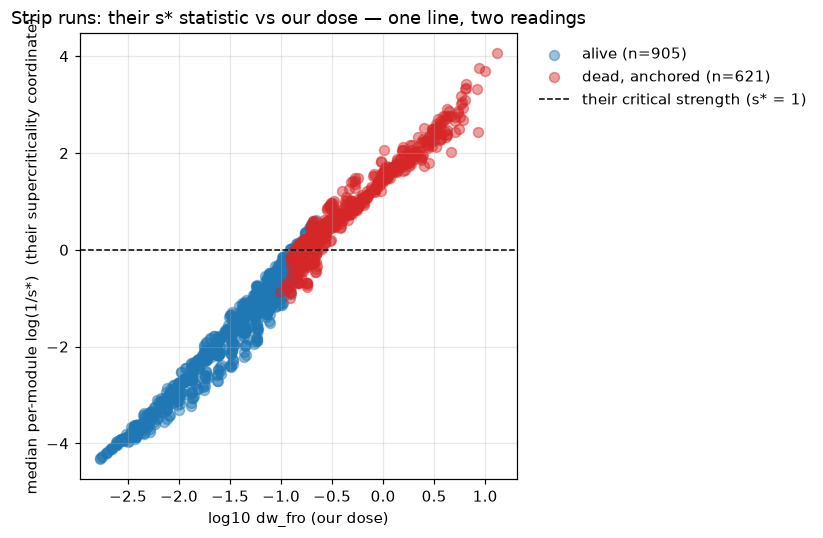

In [6]:
# The collinearity picture: why their statistic scores well on trained populations.
# Row unit: strip run (finite scores only); color = anchored fate; guide = margin 0 (=1x threshold).
fin = scan[np.isfinite(scan.dw_fro) & np.isfinite(scan.med_logmargin_full)]
dead = fin.delta_ce > DC_DS1
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(np.log10(fin.dw_fro[~dead]), fin.med_logmargin_full[~dead], s=42, alpha=.45,
           c='tab:blue', label=f'alive (n={int((~dead).sum())})')
ax.scatter(np.log10(fin.dw_fro[dead]), fin.med_logmargin_full[dead], s=42, alpha=.45,
           c='tab:red', label=f'dead, anchored (n={int(dead.sum())})')
ax.axhline(0, color='k', lw=1, ls='--', label='their critical strength (s* = 1)')
ax.set_xlabel('log10 dw_fro (our dose)')
ax.set_ylabel('median per-module log(1/s*)  (their supercriticality coordinate)')
ax.set_title('Strip runs: their s* statistic vs our dose — one line, two readings')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.tight_layout(); plt.show()

## §4 Direction injection — the {k=1, 16} × {random, W₀-aligned} corners: their four shapes, plus the readout they didn't take

`three_shape_surgery_ds1.json` (08-23) reproduces their synthetic-surgery design —
{concentrated, diffuse r=16 at θ̄/√k per direction} × {generic, W₀-top-aligned}, equal
per-module ‖Δ‖_F = E·θ̄ into all 48 modules simultaneously — extended from their single
strength (2θ̄) to E ∈ {0.5, 1, 2, 4, 8}, and adds the **behavioral readout per shape**
(Pile-probe KL; KL-era artifact, no ΔCE re-measurement), which their paper does not take. Their
*formation* predictions are expected to verify (cg pops first, dg ~√k later, aligned
never); the question is whether damage follows. Row unit below: one injection condition
(shape × E); intruders = spot-check on 8/48 modules (stride 6).

Pile-probe KL (nats) by shape x E   [cg conc-generic | ca conc-aligned | dg diff-generic | da diff-aligned]
cond     ca     cg     da     dg
E                               
0.5    0.91   7.83   0.57   5.88
1.0    3.71  10.62   3.03  10.60
2.0   10.27  12.03   7.62  13.07
4.0   13.86  16.47  11.37  15.13
8.0   12.63  14.63  12.91  16.43

intruder-positive modules (of 8 spot-checked)
cond   ca   cg   da   dg
E                       
0.5   0/8  3/8  0/8  1/8
1.0   0/8  8/8  0/8  2/8
2.0   0/8  8/8  0/8  6/8
4.0   0/8  8/8  0/8  8/8
8.0   0/8  8/8  0/8  8/8


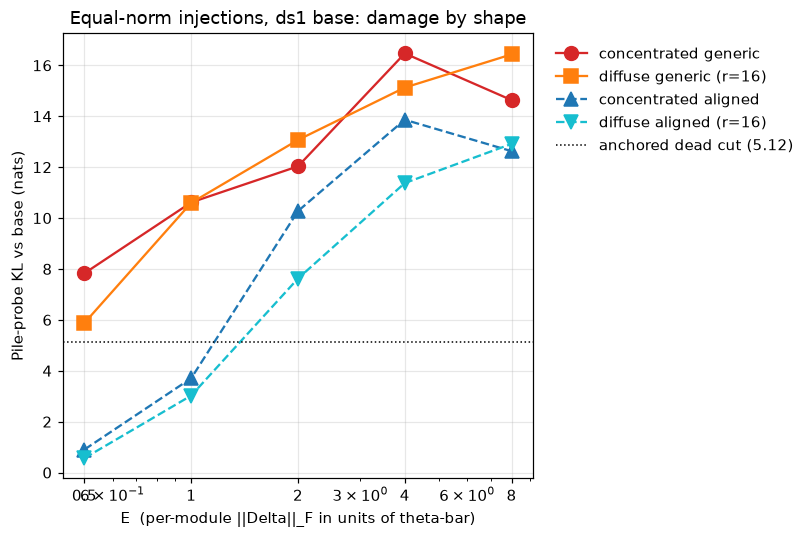


Formation verifies: cg 8/8 at E=1; dg delayed (2/8 at E=1, 8/8 at E=4); aligned never (ca 0/8, da 0/8 at E=8).
Damage does not follow: dg ~= cg at every E (E=1: 10.6 vs 10.62); aligned kills with ZERO intruders (ca E=2: 10.27, E=4: 13.86); position is a real low-E modifier (E=0.5: cg 7.83 vs ca 0.91).


In [7]:
ts = json.loads((A / 'three_shape_surgery_ds1.json').read_text())
t3 = pd.DataFrame(ts['results'])
piv = t3.pivot_table(index='E', columns='cond', values='kl')
intr = t3.pivot_table(index='E', columns='cond', values='intruder_mods', aggfunc='first')
print('Pile-probe KL (nats) by shape x E   [cg conc-generic | ca conc-aligned | dg diff-generic | da diff-aligned]')
print(piv.round(2).to_string())
print('\nintruder-positive modules (of 8 spot-checked)')
print(intr.to_string())

fig, ax = plt.subplots(figsize=(7.5, 5))
styles = dict(cg=('tab:red', 'o', '-'), dg=('tab:orange', 's', '-'),
              ca=('tab:blue', '^', '--'), da=('tab:cyan', 'v', '--'))
names = dict(cg='concentrated generic', dg='diffuse generic (r=16)',
             ca='concentrated aligned', da='diffuse aligned (r=16)')
for cond, (c, m, ls) in styles.items():
    g = t3[t3.cond == cond].sort_values('E')
    ax.plot(g.E, g.kl, marker=m, ms=9, color=c, ls=ls, label=names[cond])
ax.axhline(DC_DS1, color='k', lw=1, ls=':', label=f'anchored dead cut ({DC_DS1:.2f})')
ax.set_xscale('log'); ax.set_xticks([0.5, 1, 2, 4, 8]); ax.set_xticklabels(['0.5','1','2','4','8'])
ax.set_xlabel('E  (per-module ||Delta||_F in units of theta-bar)')
ax.set_ylabel('Pile-probe KL vs base (nats)')
ax.set_title('Equal-norm injections, ds1 base: damage by shape')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.tight_layout(); plt.show()

r = piv.round(2)
print(f"\nFormation verifies: cg {intr.loc[1.0,'cg']} at E=1; dg delayed ({intr.loc[1.0,'dg']} at E=1, "
      f"{intr.loc[4.0,'dg']} at E=4); aligned never (ca {intr.loc[8.0,'ca']}, da {intr.loc[8.0,'da']} at E=8).")
print(f"Damage does not follow: dg ~= cg at every E (E=1: {r.loc[1.0,'dg']} vs {r.loc[1.0,'cg']}); "
      f"aligned kills with ZERO intruders (ca E=2: {r.loc[2.0,'ca']}, E=4: {r.loc[4.0,'ca']}); "
      f"position is a real low-E modifier (E=0.5: cg {r.loc[0.5,'cg']} vs ca {r.loc[0.5,'ca']}).")

## §5 Direction injection — concentration sweeps (total-size-matched, with the strength-matched control)

The 2×2 used one diffuse rank; real updates live at stable rank 1–6. The refinement
sweeps k ∈ {1…32} in the two complementary matchings (`diffuse_ladder_surgery.py`):
**matched-Frobenius** (‖Δ‖_F = E·θ̄ pinned, per-direction σ = E·θ̄/√k — their
per-direction account predicts the damage onset moves right by √k; an energy account
predicts flat) and **matched-σ** (per-direction σ = E·θ̄ pinned, ‖Δ‖_F grows as √k — a
σ₁ account predicts flat; energy predicts √k growth). ΔCE-primary artifacts, all-48
intruder counts, ds1 base with the matched-F ladder replicated on orig. Row unit: one
injection condition (position × k × E).

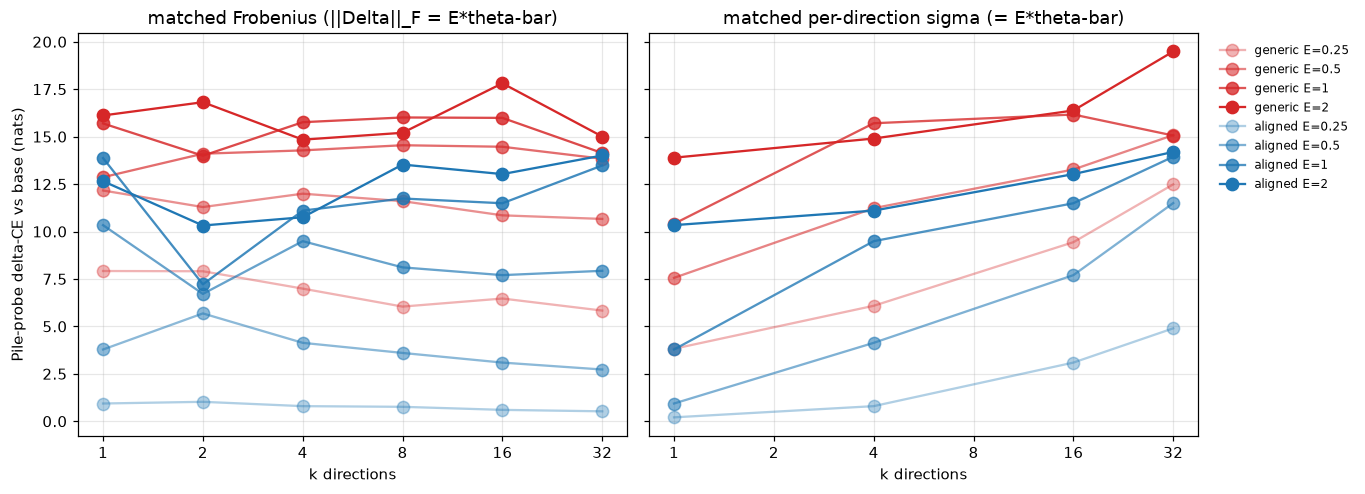

matched-F, generic, E=1: damage vs intruders across k
 k  delta_ce intruder_mods
 1     12.16         40/48
 2     11.29         43/48
 4     11.99         33/48
 8     11.60         14/48
16     10.85         11/48
32     10.66          7/48
-> damage 12.2 -> 10.7 (flat) while intruder modules 40/48 -> 7/48 and per-direction strength (theta-bar units) falls 5.7x

equal-total-energy correspondence (sigma-matched row vs fro-matched row):
align  k  E_sigma  E_fro  delta_ce_sigma  delta_ce_fro
    g  1     0.50    0.5            7.56          7.92
    g  1     1.00    1.0           10.41         12.16
    g  1     2.00    2.0           13.89         12.86
    g  4     0.25    0.5            6.09          6.99
    g  4     0.50    1.0           11.23         11.99
    g  4     1.00    2.0           15.71         14.28
    g  4     2.00    4.0           14.90         15.76
    g 16     0.25    1.0            9.44         10.85
    g 16     0.50    2.0           13.27         14.47
    g 16 

In [8]:
dl = pd.DataFrame(json.loads((A / 'diffuse_ladder_surgery_ds1_ce.json').read_text())['results'])
sm = pd.DataFrame(json.loads((A / 'specmatch_ladder_surgery_ds1_ce.json').read_text())['results'])
for d in (dl, sm):
    d['ifrac'] = d.intruder_mods.map(intr_frac)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for ax, d, ttl in [(axes[0], dl, 'matched Frobenius (||Delta||_F = E*theta-bar)'),
                   (axes[1], sm, 'matched per-direction sigma (= E*theta-bar)')]:
    for al, c in [('g', 'tab:red'), ('a', 'tab:blue')]:
        for E, alp in zip(sorted(d.E.unique()), np.linspace(.35, 1, d.E.nunique())):
            g = d[(d['align'] == al) & (d.E == E)].sort_values('k')
            ax.plot(g.k, g.delta_ce, marker='o', ms=8, color=c, alpha=alp,
                    label=f"{'generic' if al=='g' else 'aligned'} E={E:g}")
    ax.set_xscale('log', base=2); ax.set_xticks([1,2,4,8,16,32]); ax.set_xticklabels([1,2,4,8,16,32])
    ax.set_xlabel('k directions'); ax.set_title(ttl)
axes[0].set_ylabel('Pile-probe delta-CE vs base (nats)')
axes[1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

g1 = dl[(dl['align'] == 'g') & (dl.E == 1)].sort_values('k')
print('matched-F, generic, E=1: damage vs intruders across k')
print(g1[['k', 'delta_ce', 'intruder_mods']].round(2).to_string(index=False))
print(f"-> damage {g1.delta_ce.iloc[0]:.1f} -> {g1.delta_ce.iloc[-1]:.1f} (flat) while "
      f"intruder modules {g1.intruder_mods.iloc[0]} -> {g1.intruder_mods.iloc[-1]} "
      f"and per-direction strength (theta-bar units) falls {np.sqrt(g1.k.iloc[-1]/g1.k.iloc[0]):.1f}x")

# matched-sigma rows re-expressed at their total energy E_f = E_s*sqrt(k): do the two
# matchings agree at equal total energy? (join where E_f lands on the fro ladder)
sm2 = sm.assign(E_f=sm.E * np.sqrt(sm.k))
j = sm2.merge(dl, left_on=['align', 'k', 'E_f'], right_on=['align', 'k', 'E'],
              suffixes=('_sigma', '_fro'))
j = j[['align', 'k', 'E_sigma', 'E_fro', 'delta_ce_sigma', 'delta_ce_fro']]
print('\nequal-total-energy correspondence (sigma-matched row vs fro-matched row):')
print(j.round(2).to_string(index=False))

In [9]:
# Second-base replication: the matched-F ladder on the orig base (pythia-160m).
# Row unit: injection condition; same construction as ds1.
do = pd.DataFrame(json.loads((A / 'diffuse_ladder_surgery_orig_ce.json').read_text())['results'])
go = do[(do['align'] == 'g') & (do.E == 1)].sort_values('k')
ao = do[(do['align'] == 'a')].pivot_table(index='E', columns='k', values='delta_ce')
print('orig base, generic E=1 (flat-in-k + intruder collapse):')
print(go[['k', 'delta_ce', 'intruder_mods']].round(2).to_string(index=False))
print('\norig base, aligned delta-CE by E x k (kills with zero intruders):')
print(ao.round(2).to_string())
print('aligned intruder counts observed:', sorted(do[do['align'] == 'a'].intruder_mods.unique()))

orig base, generic E=1 (flat-in-k + intruder collapse):
 k  delta_ce intruder_mods
 1     13.24         42/48
 2     14.50         46/48
 4     13.93         30/48
 8     12.80         19/48
16     11.33         11/48
32     11.19          8/48

orig base, aligned delta-CE by E x k (kills with zero intruders):
k       1     2      4      8      16     32
E                                           
0.5   1.06  1.36   0.98   1.17   1.10   1.05
1.0   3.88  4.52   4.09   4.72   5.46   5.68
2.0  13.25  6.57   8.96   9.92  14.20  12.75
4.0  18.32  8.39  13.77  16.16  18.94  19.77
8.0  17.96  8.81  11.82  19.56  19.68  22.38
aligned intruder counts observed: ['0/48']


## §6 Direction injection — trained-update-aligned source: learned directions at synthetic size

`trained_direction_ladder_ds1_ce.json` (08-26): the same equal-energy shapes as §5
(uniform E·θ̄/√k per module — which removes the donor's module-allocation as a
confound), but the k directions per module are the top-k singular directions of a real
donor adapter's ΔW. Two donors: one dead r128 run, one alive r128 run. Prediction under
"learned directions carry the damage": trained ≫ random at matched energy. Prediction
under the intruder account: damage should track intruder formation. Row unit: injection
condition; random comparator = the §5 matched-F generic row at the same (k, E);
intruders spot-checked on 8/48 modules. Caveat: KL/ΔCE saturates and goes non-monotone
on these rows at E = 4.

delta-CE (nats) at matched per-module energy E*theta-bar over k donor directions
 k   E  tdead  talive  random tdead_intr talive_intr intr_random
 1 0.5   10.7    11.7     7.9        1/8         3/8       24/48
 1 1.0   14.3    14.7    12.2        7/8         7/8       40/48
 1 2.0   17.5    16.1    12.9        8/8         8/8       48/48
 1 4.0   16.5    18.6    15.7        8/8         8/8       48/48
 4 0.5    9.8     9.7     7.0        2/8         2/8       11/48
 4 1.0   14.0    13.6    12.0        5/8         6/8       33/48
 4 2.0   16.5    15.6    14.3        8/8         8/8       47/48
 4 4.0   18.6    16.1    15.8        8/8         8/8       48/48
16 0.5   11.5    27.1     6.5        1/8         1/8        3/48
16 1.0   29.8    41.5    10.9        2/8         2/8       11/48
16 2.0   37.5    42.7    14.5        7/8         7/8       32/48
16 4.0   19.4    24.4    16.0        8/8         8/8       48/48
32 0.5   13.2    15.9     5.8        0/8         0/8        1/48
32 1.0   

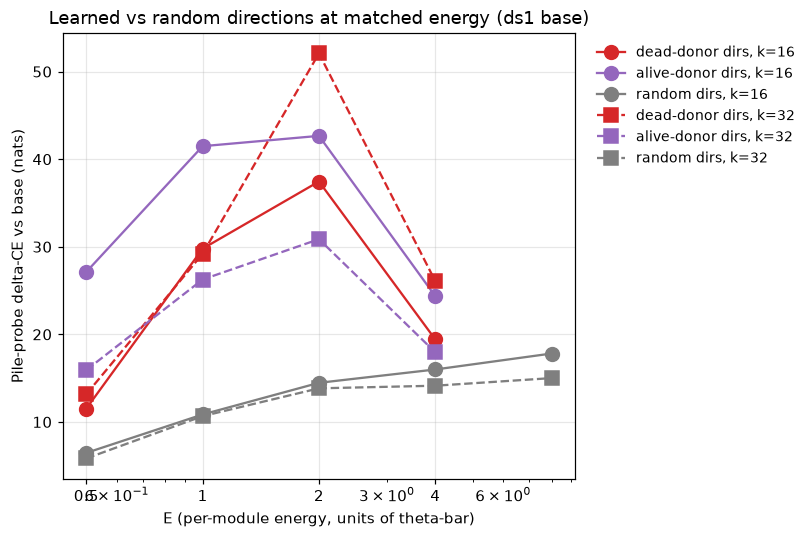

In [10]:
td = pd.DataFrame(json.loads((A / 'trained_direction_ladder_ds1_ce.json').read_text())['results'])
rnd = dl[dl['align'] == 'g'][['k', 'E', 'delta_ce', 'intruder_mods']].rename(
    columns={'delta_ce': 'random', 'intruder_mods': 'intr_random'})
w = td.pivot_table(index=['k', 'E'], columns='cond', values='delta_ce').reset_index()
wi = td.pivot_table(index=['k', 'E'], columns='cond', values='intruder_mods',
                    aggfunc='first').reset_index()
tab = (w.merge(wi, on=['k', 'E'], suffixes=('', '_intr'))
        .merge(rnd, on=['k', 'E'], how='left'))
tab = tab[['k', 'E', 'tdead', 'talive', 'random', 'tdead_intr', 'talive_intr', 'intr_random']]
print('delta-CE (nats) at matched per-module energy E*theta-bar over k donor directions')
print(tab.round(1).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
for k, mk in [(16, 'o'), (32, 's')]:
    for cond, c, nm in [('tdead', 'tab:red', 'dead-donor dirs'),
                        ('talive', 'tab:purple', 'alive-donor dirs')]:
        g = td[(td.cond == cond) & (td.k == k)].sort_values('E')
        ax.plot(g.E, g.delta_ce, marker=mk, ms=9, color=c,
                ls='-' if k == 16 else '--', label=f'{nm}, k={k}')
    g = rnd[rnd.k == k].sort_values('E')
    ax.plot(g.E, g.random, marker=mk, ms=9, color='tab:gray',
            ls='-' if k == 16 else '--', label=f'random dirs, k={k}')
ax.set_xscale('log'); ax.set_xticks([0.5, 1, 2, 4]); ax.set_xticklabels(['0.5','1','2','4'])
ax.set_xlabel('E (per-module energy, units of theta-bar)')
ax.set_ylabel('Pile-probe delta-CE vs base (nats)')
ax.set_title('Learned vs random directions at matched energy (ds1 base)')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

## §7 Real updates: the direction surgery's intruder pass

The dissociation on *trained* adapters (`position_surgery_v2_intr.jsonl`): each run's
update re-assembled at its exact trained spectrum under three positions (orig / random /
W₀-aligned) with all-48-module intruder counts per variant. If intruders carried the
damage, the healing random rotation should have removed them and the aligned variant
(zero intruders by construction) should be safest. Row unit: run (intruder-pass subset,
KL-era readout); table = medians over runs whose ORIG variant is dead at that run's
receiver-anchored cut; trait column = mean test p(dog) over the same runs (secondary
readout).

In [11]:
pi = read_jsonl(A / 'position_surgery_v2_intr.jsonl')
pi['ifrac'] = pi.intruder_mods.map(intr_frac)
cuts = {b: anchored_dead_cut(OUT, b) for b in pi.base.unique()}
orig_dead = pi[(pi.variant == 'orig') &
               (pi.pile_kl > pi.base.map(cuts))].run.unique()
sub = pi[pi.run.isin(orig_dead)]
med = sub.groupby('variant').agg(n=('run', 'size'), med_kl=('pile_kl', 'median'),
                                 med_intruder_frac=('ifrac', 'median'),
                                 mean_p_dog=('p_target', 'mean'))
print(f'{len(orig_dead)} runs dead at orig (of {pi.run.nunique()} in the intruder pass); '
      'medians over those runs per variant:')
print(med.round(3).to_string())
km = med.med_kl; im = med.med_intruder_frac
print(f"\nBoth directions of the dissociation, on real updates:")
print(f"  healing keeps the intruders: rand0 KL {km['orig']:.1f} -> {km['rand0']:.1f} while "
      f"intruder fraction stays {im['orig']:.2f} -> {im['rand0']:.2f}")
print(f"  zero intruders still damages: align has {im['align']:.2f} intruder fraction "
      f"at KL {km['align']:.1f} — more damage with none than rand0 causes with "
      f"{im['rand0']:.0%} of modules intruder-positive")

12 runs dead at orig (of 24 in the intruder pass); medians over those runs per variant:
          n  med_kl  med_intruder_frac  mean_p_dog
variant                                           
align    12   5.822              0.000       0.000
orig     12  12.525              0.854       0.000
rand0    12   2.251              0.875       0.002

Both directions of the dissociation, on real updates:
  healing keeps the intruders: rand0 KL 12.5 -> 2.3 while intruder fraction stays 0.85 -> 0.88
  zero intruders still damages: align has 0.00 intruder fraction at KL 5.8 — more damage with none than rand0 causes with 88% of modules intruder-positive


## §7b The direction surgery at population scale: selectors × rotation amount (08-29 campaign)

Every variant of the direction surgery, on the **denominator-valid population** (546
runs: the census runs whose Randomized variant is itself a functioning model —
strip 141 / same-model 83 / trait-free 61 / teachers 147 / 410m same-model 67 /
410m cross 47). Records: `position_surgery_sub_*` (the t = 1 endpoints) and
`position_surgery_subt_*` (rotation amounts t ∈ {0.25, 0.5, 0.75}). Selectors and
their names: **Top-k randomized** (`top{k}`), **Bottom randomized (top-k kept)**
(`rest{k}`), **Supercritical randomized** (`super`, pairs with σᵢ > θ̄ of their module
— the intruder-threshold law's dangerous class), **Subcritical randomized** (`sub`),
**Top-k supercritical randomized** (`stop{k}`). The run's own damage (`stored`, its
probe) and its Randomized variant (`rand0`, from the census) bracket every curve.
Row unit in the tables: run; aggregation: median (damage) / fraction (revival =
variant ΔCE below the receiver's anchored cut) within arm, **dead runs only**
(stored > cut) unless stated. The trait readout p(dog) rides on every variant.

In [12]:
import glob as _glob
def _sd(run):
    try:
        return json.loads((Path(run) / 'eval' / 'pile_probe.json').read_text()).get('delta_ce')
    except FileNotFoundError:
        return np.nan
ARMS7 = ['strip', 'samemodel', 'traitfree', 'teachers', 'm410same', 'm410cross']
CUTS7 = {b: anchored_dead_cut(OUT, b) for b in
         ['pythia-160m', 'pythia-160m-data-seed1', 'pythia-410m', 'pythia-410m-seed1']}
rows = []
for arm in ARMS7:
    for pat in (f'position_surgery_sub_{arm}_s*.jsonl', f'position_surgery_subt_{arm}_s*.jsonl'):
        for f in _glob.glob(str(A / pat)):
            df_ = read_jsonl(f); df_['arm'] = arm; rows.append(df_)
ds = pd.concat(rows, ignore_index=True)
ds['sel'] = ds.variant.str.split('@').str[0]
ds['t'] = ds.variant.str.split('@').str[1].fillna('1').astype(float)
ds['cut'] = ds.base.str.split('/').str[-1].map(CUTS7)
ds['stored'] = ds.run.map({r: _sd(r) for r in ds.run.unique()})
cen7 = pd.concat([read_jsonl(f) for arm in ARMS7
                  for f in _glob.glob(str(A / f'position_surgery_cen_{arm}_*.jsonl'))])
ds['rand0'] = ds.run.map(cen7[cen7.variant == 'rand0'].groupby('run').delta_ce.first())
ds['dead'] = ds.stored > ds.cut
ds['revived'] = ds.delta_ce < ds.cut
print(f"{len(ds)} records over {ds.run.nunique()} runs; dead runs: {ds[ds.dead].run.nunique()}")
SEL_ORDER = ['top1', 'top2', 'top4', 'rest1', 'rest2', 'rest4', 'super', 'sub', 'stop1', 'stop2', 'stop4']
dd = ds[ds.dead & (ds.t == 1)]
base7 = dd.drop_duplicates('run').groupby('arm').agg(n=('run', 'size'), stored=('stored', 'median'),
                                                    randomized=('rand0', 'median'))
tab_med = dd.pivot_table(index='arm', columns='sel', values='delta_ce', aggfunc='median')[SEL_ORDER]
tab_rev = dd.pivot_table(index='arm', columns='sel', values='revived', aggfunc='mean')[SEL_ORDER]
print('\nDEAD runs, t = 1 endpoints — median delta-CE (nats) after randomizing the selector; '
      'columns stored / randomized = the run itself / its Randomized variant:')
print(pd.concat([base7.round(1), tab_med.round(1)], axis=1).to_string())
print('\nrevival fraction (variant delta-CE below the anchored cut):')
print((tab_rev * 100).round(0).astype('Int64').astype(str).add('%').to_string())

19192 records over 546 runs; dead runs: 366

DEAD runs, t = 1 endpoints — median delta-CE (nats) after randomizing the selector; columns stored / randomized = the run itself / its Randomized variant:
             n  stored  randomized  top1  top2  top4  rest1  rest2  rest4  super  sub  stop1  stop2  stop4
arm                                                                                                       
m410cross   22     8.9         0.9   3.8   2.2   1.1    2.0    3.3    5.8    5.7  1.5    6.4    5.7    6.2
m410same    39    11.6         2.6   5.8   3.5   2.4    4.2    6.8   10.3    7.6  3.7    7.9    7.9    7.9
samemodel   53    11.9         2.8   5.3   3.7   2.6    6.5    8.2   10.3    5.4  5.5    7.2    5.9    6.1
strip       99    12.2         2.2   4.9   3.2   2.3    5.2    6.1    8.3    6.0  3.5    7.1    6.6    6.0
teachers   126    32.7         0.0   0.4   0.2   0.1   27.6   32.1   32.5   32.7  0.0   86.0   86.0   86.0
traitfree   27     9.4         3.6   5.1   4.1   3.

In [13]:
# The direction-resolved verdict on the intruder mechanism: their prediction is that
# randomizing the SUPERcritical pairs revives and the SUBcritical pairs are inert.
sv = dd.drop_duplicates('run').groupby('arm').apply(
    lambda g: pd.Series(dict(runs_with_any_super=(g.n_super > 0).mean(),
                             median_super_frac=(g.n_super / g.n_dirs).median())))
sv['super_revives'] = dd[dd.sel == 'super'].groupby('arm').revived.mean()
sv['sub_revives'] = dd[dd.sel == 'sub'].groupby('arm').revived.mean()
sv['n_super_rows'] = dd[dd.sel == 'super'].groupby('arm').size()
print('DEAD runs: share with any supercritical direction, median supercritical fraction of pairs,')
print('and revival after randomizing ONLY that class (super) vs ONLY its complement (sub):')
print(sv.round(2).to_string())
t_ = sv.loc['teachers']
print(f"\nTeachers: {t_.runs_with_any_super:.0%} of dead teachers have ANY supercritical direction; "
      f"Supercritical randomized revives {t_.super_revives:.0%}, Subcritical randomized revives {t_.sub_revives:.0%}.")
print('Student arms: sub >= super everywhere:',
      all(sv.loc[a, 'sub_revives'] >= sv.loc[a, 'super_revives'] - 0.02 for a in sv.index))

DEAD runs: share with any supercritical direction, median supercritical fraction of pairs,
and revival after randomizing ONLY that class (super) vs ONLY its complement (sub):
           runs_with_any_super  median_super_frac  super_revives  sub_revives  n_super_rows
arm                                                                                        
m410cross                 0.95               0.02           0.41         0.91            22
m410same                  1.00               0.04           0.31         0.62            39
samemodel                 1.00               0.09           0.40         0.42            53
strip                     0.98               0.06           0.36         0.66            99
teachers                  0.02               0.00           0.00         1.00           126
traitfree                 1.00               0.05           0.59         0.74            27

Teachers: 2% of dead teachers have ANY supercritical direction; Supercritical randomized

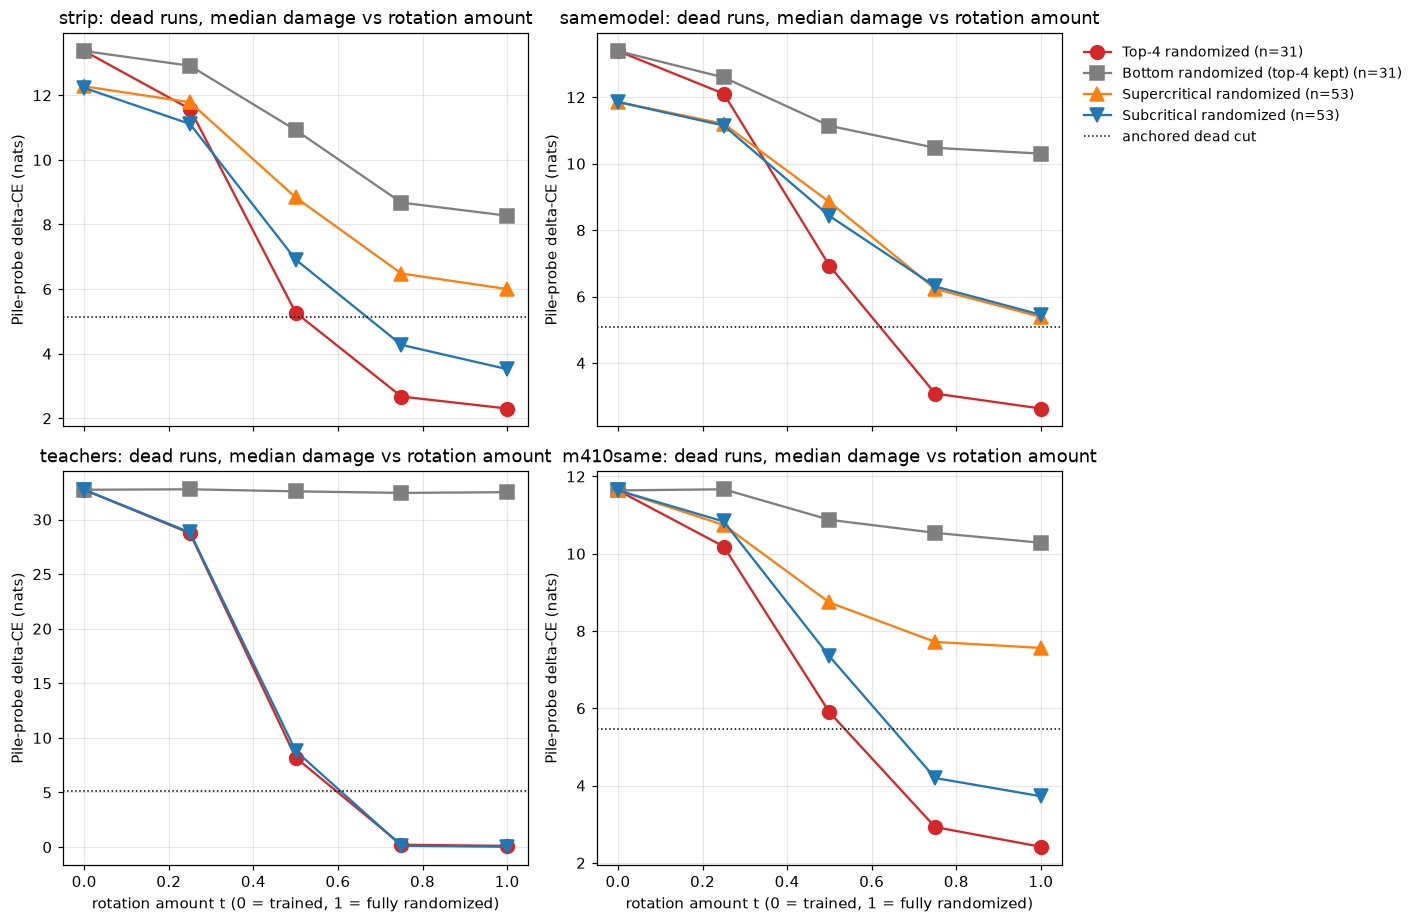

fraction of dead runs whose damage is monotone non-increasing in t (0.5-nat tolerance):
selector   Bottom randomized (top-4 kept)  Subcritical randomized  Supercritical randomized  Top-4 randomized
arm                                                                                                          
m410same                             0.97                    0.95                      0.95               1.0
samemodel                            0.97                    0.87                      0.98               1.0
strip                                0.95                    0.97                      0.91               1.0
teachers                             0.98                    1.00                       NaN               1.0


In [14]:
# Rotation amount: median delta-CE vs t per selector (dead runs), t = 0 drawn as the run's
# own damage. Panels = arms; one line per selector; right-margin legend.
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
styles = dict(top4=('tab:red', 'o'), rest4=('tab:gray', 's'), super=('tab:orange', '^'), sub=('tab:blue', 'v'))
names = dict(top4='Top-4 randomized', rest4='Bottom randomized (top-4 kept)',
             super='Supercritical randomized', sub='Subcritical randomized')
mono_rows = []
for ax, arm in zip(axes.ravel(), ['strip', 'samemodel', 'teachers', 'm410same']):
    g = ds[ds.dead & (ds.arm == arm)]
    for sel, (c, m) in styles.items():
        w = g[g.sel == sel].pivot_table(index='run', columns='t', values='delta_ce').dropna()
        if len(w) < 5:
            continue
        ts = [0.0] + sorted(w.columns)
        ys = [g.drop_duplicates('run').set_index('run').loc[w.index, 'stored'].median()] + \
             [w[c_].median() for c_ in sorted(w.columns)]
        ax.plot(ts, ys, marker=m, ms=9, color=c, label=f'{names[sel]} (n={len(w)})')
        mono_rows.append(dict(arm=arm, selector=names[sel], n=len(w),
                              monotone_nonincreasing=(np.diff(w[sorted(w.columns)].values, axis=1) <= 0.5).all(axis=1).mean()))
    ax.axhline(CUTS7['pythia-160m' if arm in ('samemodel', 'teachers') else
               'pythia-160m-data-seed1' if arm == 'strip' else 'pythia-410m'],
               color='k', ls=':', lw=1, label='anchored dead cut')
    ax.set_title(f'{arm}: dead runs, median damage vs rotation amount'); ax.set_ylabel('Pile-probe delta-CE (nats)')
for ax in axes[1]:
    ax.set_xlabel('rotation amount t (0 = trained, 1 = fully randomized)')
axes[0, 1].legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print('fraction of dead runs whose damage is monotone non-increasing in t (0.5-nat tolerance):')
print(pd.DataFrame(mono_rows).pivot_table(index='arm', columns='selector', values='monotone_nonincreasing').round(2).to_string())

In [15]:
# Teachers: where does the damage live vs where does the trait live?
# Row unit: dead teacher run (n = 126); per selector at t = 1: median damage and mean p(dog).
tg = ds[ds.dead & (ds.arm == 'teachers') & (ds.t == 1)]
tt = tg.groupby('sel').agg(n=('run', 'size'), median_delta_ce=('delta_ce', 'median'),
                           mean_p_dog=('p_target', 'mean')).reindex(
    [s_ for s_ in SEL_ORDER if s_ in tg.sel.unique()])
print('dead teachers, stored damage median %.1f nats, p(dog) at stored ~ 1.0 (saturated):' %
      tg.drop_duplicates('run').stored.median())
print(tt.round(3).to_string())
r = tt.median_delta_ce; q = tt.mean_p_dog
print(f"\nDamage needs direction 1: Top-1 randomized -> {r['top1']:.1f} nats (from {tg.drop_duplicates('run').stored.median():.1f}); "
      f"keep only direction 1 trained (rest1) -> {r['rest1']:.1f} nats.")
print(f"Trait is redundant over directions 1 and 2: p(dog) after top1 {q['top1']:.2f}, rest1 {q['rest1']:.2f}, "
      f"top2 {q['top2']:.2f}, top4 {q['top4']:.2f}.")

dead teachers, stored damage median 32.7 nats, p(dog) at stored ~ 1.0 (saturated):
         n  median_delta_ce  mean_p_dog
sel                                    
top1   126            0.371       0.914
top2   126            0.233       0.177
top4   126            0.109       0.026
rest1  126           27.636       0.798
rest2  126           32.131       1.000
rest4  126           32.503       1.000
super  126           32.722       1.000
sub    126            0.028       0.010
stop1    2           86.009       1.000
stop2    2           86.019       1.000
stop4    2           86.022       1.000

Damage needs direction 1: Top-1 randomized -> 0.4 nats (from 32.7); keep only direction 1 trained (rest1) -> 27.6 nats.
Trait is redundant over directions 1 and 2: p(dog) after top1 0.91, rest1 0.80, top2 0.18, top4 0.03.


## §8 Shuttleworth et al. (arXiv:2410.21228): faithfulness, and the Fig. 8 paragraph adjudicated

**Their claims** (the intervention paragraph, quoted verbatim from the PDF, decomposed):

- **S1** Scaling down the top intruder dimension of each weight matrix (SVD W′ = W₀+ΔW,
  scale that singular value by λ < 1) reduces forgetting substantially with minimal
  fine-tuning test-accuracy cost (LLaMA2-7B/MetaMath r256, λ=0.3: −0.1% accuracy,
  −33.3% forgetting; RoBERTa/QQP, λ=0.7: equal accuracy, −33.2% forgetting).
- **S2** λ > 1 (amplifying intruders) increases forgetting; occasionally accuracy
  *improves* as forgetting drops.
- **S3** Specificity control (their Fig. 12): scaling down *pretrained* singular vectors
  of similar σ (matched contribution) *increases* forgetting — so the effect is
  "exclusive to intruder dimensions."
- **S4** Conclusion: "the forgetting observed in LoRA is **caused by intruder dimensions
  interfering** with the pre-trained language modeling capabilities."
- **S5** "The scale (singular value) of these intruder dimensions is not essential for
  the fine-tuning task performance."

**Faithfulness of our implementation to Shuttleworth.**

| Component | Theirs | Ours | Verdict |
|---|---|---|---|
| Intruder detection | top-k singular vectors of the fine-tuned matrix, max cosine overlap vs all pretrained vectors below a threshold; (k, ε) swept | identical operationalization at the fixed point (k=10, τ=0.5) the threshold paper also uses; exact core-matrix computation | **Faithful** (fixed point of their swept ranges; τ ∈ {0.3, 0.7} sensitivity not re-run) |
| Fig. 8 intervention | SVD W′, scale the top intruder's σ by λ ∈ {0.3…0.9, >1} | **not implemented** — our λ interventions rescale the *whole update* (every direction, no SVD of W′) | Not replicated verbatim; our version is the deconfounded size axis |
| Fig. 12 control | scale down a *pretrained* singular vector of similar σ | **not implemented** | Not replicated; reinterpreted below |
| Task readout | benchmark accuracy on the fine-tuning task (MetaMath, QQP, …) | exact next-token trait probability p(dog) | Different object, same role (the trained channel) |
| Regime | task fine-tuning on LLaMA2-7B / RoBERTa-base; LoRA **and full FT** | numbers distillation on Pythia-160m bases; **all-LoRA** | Their full-FT contrast untested here (flagged as the high-leverage gap) |

**The confound their design cannot see.** Shrinking the top intruder's σ removes update
*energy* and that direction's *contribution* together — W′ loses (1−λ)·σ·uvᵀ, and since
real LoRA updates are low-stable-rank, the top intruder carries a large share of the
update's Frobenius energy. "Shrink the intruder" ≈ "shrink the update," so S1/S2 are
predicted by the size factor alone. Their Fig. 12 control matches the *norm change* but
intervenes on a **different object**: deleting part of a pretrained direction damages
W₀'s own computation (of course pretraining loss rises). The contrast it establishes is
"removing update energy ≠ removing base energy" — true, but silent on whether
*novelty* is the toxic property. The control that isolates intruder-ness — remove equal
update energy at a non-novel position — is what the spectrum-preserving surgeries
(§4–§7) effectively run, and it flips the verdict. The cell below computes the
claim-by-claim adjudication live from this notebook's artifacts.

In [16]:
# S1/S2 corroboration from the lambda-crossing ladders (eval-time ΔW -> λ·ΔW; ce-wave
# artifacts; per-(run, λ) rows carry delta_ce AND p(dog)). Row unit: run (boundary-band,
# 24/arm); λ grid 0.25–2.8. 'single switch' = the alive->dead transition along λ happens
# once (the integrity event moves monotonically); 'λ=0.7 helps' = damage falls vs λ=1
# while p(dog) does not fall (their λ=0.7 row); trait peak ratio = argmax-λ of p(dog)
# over the λ where damage crosses the anchored cut ('<=' = peak at grid minimum,
# left-censored).
def lam_arm(path, trait):
    df = read_jsonl(A / path)
    cuts_ = {b: anchored_dead_cut(OUT, b) for b in df.base.unique()}
    out = []
    for run, g in df.groupby('run'):
        g = g.sort_values('lam')
        cut = cuts_[g.base.iloc[0]]
        dead_seq = (g.delta_ce > cut).values
        single = (np.diff(dead_seq.astype(int)) >= 0).all() and dead_seq.any()
        lam_cross = np.nan
        if dead_seq.any() and not dead_seq[0]:
            i = int(np.argmax(dead_seq))
            x0, x1 = np.log(g.lam.values[i-1]), np.log(g.lam.values[i])
            y0, y1 = g.delta_ce.values[i-1], g.delta_ce.values[i]
            lam_cross = float(np.exp(x0 + (cut - y0) / (y1 - y0) * (x1 - x0)))
        r07, r10 = g[g.lam == 0.7].iloc[0], g[g.lam == 1.0].iloc[0]
        helps = (r07.delta_ce < r10.delta_ce) and (r07.p_target >= r10.p_target)
        lam_peak = float(g.lam.values[np.argmax(g.p_target.values)]) if trait else np.nan
        out.append(dict(run=run, single=single, lam_cross=lam_cross, helps=helps,
                        lam_peak=lam_peak, censored=trait and lam_peak == g.lam.min()))
    return pd.DataFrame(out)

summ = {}
for path, name, trait in [('lambda_crossing_ce_strip.jsonl', 'strip', True),
                          ('lambda_crossing_ce_samemodel.jsonl', 'same-model', True),
                          ('lambda_crossing_ce_traitfree.jsonl', 'trait-free', False)]:
    d = lam_arm(path, trait)
    ratio = (d.lam_peak / d.lam_cross).dropna()
    summ[name] = dict(
        n=len(d), single_switch=f'{int(d.single.sum())}/{int(d.single.count())}',
        lam07_helps=f'{int(d.helps.sum())}/{len(d)}',
        med_peak_over_cross=(f'<= {ratio.median():.2f}' if d.censored.any()
                             else f'{ratio.median():.2f}') if trait else '—',
        peak_below_cross=f'{int((ratio < 1).sum())}/{len(ratio)}' if trait else '—')
lam_summary = pd.DataFrame(summ).T
print(lam_summary.to_string())
print("\nReading: rescaling the WHOLE update reproduces their Fig. 8 phenomenology — "
      "single integrity event in λ,\ndamage falls at λ=0.7 with no trait cost (often a "
      "trait GAIN: the trait optimum sits below the integrity crossing).")

             n single_switch lam07_helps med_peak_over_cross peak_below_cross
strip       24         24/24       14/24             <= 0.53            23/24
same-model  24         24/24        7/24                0.93            17/24
trait-free  24         24/24       24/24                   —                —

Reading: rescaling the WHOLE update reproduces their Fig. 8 phenomenology — single integrity event in λ,
damage falls at λ=0.7 with no trait cost (often a trait GAIN: the trait optimum sits below the integrity crossing).


In [17]:
# The claim-by-claim adjudication, each row anchored by a number computed in this
# notebook (variables from §4–§7 and the λ cell above).
g1_drop = f"{g1.delta_ce.iloc[0]:.1f}->{g1.delta_ce.iloc[-1]:.1f} nats over k 1->32 " \
          f"({g1.intruder_mods.iloc[0]} -> {g1.intruder_mods.iloc[-1]} intruder modules)"
adj = pd.DataFrame([
    ('S1 shrink update -> less forgetting, task kept', 'CORROBORATED (as a SIZE effect)',
     f"single integrity switch {summ['strip']['single_switch']} strip / "
     f"{summ['trait-free']['single_switch']} trait-free; lam=0.7 helps "
     f"{summ['strip']['lam07_helps']} (strip)"),
    ('S2 amplify -> more forgetting; accuracy can improve', 'CORROBORATED',
     f"trait peak below the integrity crossing in {summ['strip']['peak_below_cross']} "
     f"strip runs (median ratio {summ['strip']['med_peak_over_cross']})"),
    ('S3 pretrained-vector control shows exclusivity', 'REINTERPRETED (not run verbatim)',
     'their control removes BASE energy, not update energy; aligned ADDITION also kills: '
     f"ca at E=2 -> {piv.loc[2.0,'ca']:.1f} nats with 0/8 intruders (§4)"),
    ('S4 intruders CAUSE the forgetting', 'DISPROVED at matched size',
     f"align kills at 0% intruders (KL {med.loc['align','med_kl']:.1f}); healing rotation "
     f"keeps {med.loc['rand0','med_intruder_frac']:.0%} intruder modules while KL "
     f"{med.loc['orig','med_kl']:.1f} -> {med.loc['rand0','med_kl']:.1f} (§7); damage flat "
     f"in k: {g1_drop} (§5)"),
    ('S5 intruder SCALE not essential to the task', 'CORROBORATED + SHARPENED',
     'the task rides direction IDENTITY: rotation with the same singular values deletes the '
     'trait (§7 mean p(dog) ~0 under rand/align on trait-bearing arms; ledger N2: '
     'same-model alive 0.485 -> 0.009, teachers 1.000 -> prior)'),
], columns=['Shuttleworth claim', 'verdict', 'live anchor'])
with pd.option_context('display.max_colwidth', 110):
    print(adj.to_string(index=False))

                                 Shuttleworth claim                          verdict                                                                                                                                                                                                                 live anchor
     S1 shrink update -> less forgetting, task kept  CORROBORATED (as a SIZE effect)                                                                                                                                         single integrity switch 24/24 strip / 24/24 trait-free; lam=0.7 helps 14/24 (strip)
S2 amplify -> more forgetting; accuracy can improve                     CORROBORATED                                                                                                                                          trait peak below the integrity crossing in 23/24 strip runs (median ratio <= 0.53)
     S3 pretrained-vector control shows exclusivity REINTERPRETED (not run verbatim) 

In [18]:
# Their observational claim on our populations: empirical intruder counts (their detection,
# tau = 0.5, top-10, left side) per run across all six arms. Row unit: run (diverged excluded).
sh = pd.concat([pd.read_csv(A / f'shuttleworth_observables_{a}.csv').assign(arm=a) for a in ARMS7])
sh = sh[~sh.diverged.astype(bool)].copy()
recv7 = dict(strip='pythia-160m-data-seed1', samemodel='pythia-160m', traitfree='pythia-160m-data-seed1',
             teachers='pythia-160m', m410same='pythia-410m', m410cross='pythia-410m-seed1')
sh['dead'] = sh.delta_ce > sh.arm.map(recv7).map(CUTS7)
from scipy.stats import spearmanr as _sp
out = []
for arm, g in sh.groupby('arm'):
    al, de = g[~g.dead], g[g.dead]
    out.append(dict(arm=arm, n=len(g), alive_median_intruders=al['nl_t0.5'].median(),
                    dead_median_intruders=de['nl_t0.5'].median(),
                    rho_count_vs_deltaCE=_sp(g['nl_t0.5'], g.delta_ce).statistic,
                    rho_count_vs_rank_alive=(_sp(al['nl_t0.5'], al['rank']).statistic if al['nl_t0.5'].nunique() > 1 else np.nan)))
print('intruder directions per run (of 10 checked per module x modules): alive vs dead medians;')
print('rank correlations: count vs damage (all runs) and count vs LoRA rank (alive runs only).')
print(pd.DataFrame(out).set_index('arm').round(2).to_string())
print('\nDissociations inside the collinearity: dead teachers carry ~1 intruder (collapse with no spectral novelty);'
      ' alive trait-free runs carry dozens (novelty without collapse).')

intruder directions per run (of 10 checked per module x modules): alive vs dead medians;
rank correlations: count vs damage (all runs) and count vs LoRA rank (alive runs only).
              n  alive_median_intruders  dead_median_intruders  rho_count_vs_deltaCE  rho_count_vs_rank_alive
arm                                                                                                          
m410cross   288                     2.0                  125.0                  0.89                    -0.43
m410same    376                     2.0                  243.0                  0.93                    -0.44
samemodel   312                     1.5                  111.5                  0.87                    -0.41
strip      1261                     1.0                  147.0                  0.91                    -0.33
teachers    288                     0.0                    1.0                  0.71                      NaN
traitfree   706                    34.0              

## §9 Verdict: where we agree, where we disagree, what remains untested

**Agreements (their mathematics and scale).**
1. The estimator transfers: their own degeneracy gate passes on 160m (§2b), and every
   *formation* prediction verifies exactly in our injections — generic-concentrated pops
   intruders from E ≈ 1, diffuse ~√k later, aligned never (§4).
2. The scale coincidence is real and striking: their RMT threshold sits at median
   θ̄/‖W₀‖_F ≈ 0.12 — numerically on top of the trained-update behavioral threshold
   θ̂ ≈ 0.13–0.14 (§2b) — and a direction must rival ~0.85·σ₁(W₀) to pop out.
3. Their supercriticality statistics (aggregates of 1/s\*) are strong observational fate predictors on our grid
   (AUC ≈ 0.97–0.98, §3) — stronger than in their own deployment task, though the tasks
   differ and the numbers must not be compared across papers.
4. Both programs find forgetting is *not* a function of raw size alone at matched norm —
   theirs across layers (240× supercritical-vs-subcritical asymmetry), ours across
   directions within layers. The results live on different axes and are compatible.

**Disagreements (their mechanism).**
1. *"Intruders cause forgetting"* fails in both causal directions here: W₀-aligned
   energy kills with zero intruders (§4, §5, and on real updates §7), and the healing
   rotation keeps ~all intruder modules while damage collapses (§7). Damage is flat in k
   while intruder counts and per-direction supercriticality vary severalfold (§5); learned-donor
   directions reach extreme damage with almost no intruders (§6).
2. *"Threshold-crossing layers, rather than update magnitude, carry the forgetting"* —
   on our grid, magnitude (Frobenius, absolute-α) is the best within-arm fate coordinate
   (§3: dw_fro and K beat every margin aggregate; the margins add ~nothing within dose
   strata, while dose retains signal within margin strata), and *direction identity* is
   the cross-arm factor. Their statistic scores well observationally because trained
   populations move along the energy–margin collinearity (§3 figure).
3. Their causal intervention is confounded for the mechanism claim: shrinking intruder
   singular values removes Frobenius energy *and* direction content together. The
   spectrum-preserving rotation deconfounds exactly this — and flips the verdict. The
   potency of learned directions is functional and invisible to every
   W₀-spectrum-referenced statistic (overlap ≈ random baseline; `collapse_claims_v2.md`
   N9).

**Shuttleworth et al. (§8).** The same shape of verdict, one generation earlier.
Corroborated as phenomena: shrinking the update reduces forgetting with the task kept
(and often improved — the trait optimum sits below the integrity crossing), amplifying
increases it; the task is robust to scale; and their premise holds — learned directions
are spectrally novel w.r.t. W₀ (overlap ≈ random baseline), so every strong learned
direction registers as an intruder. Disproved: the causal attribution. Their Fig. 8
intervention removes energy and direction together, so its results are predicted by the
size factor alone; deconfounded at exactly preserved spectrum, intruder-ness is neither
necessary nor sufficient for the damage (§7), and their Fig. 12 control distinguishes
update-energy removal from base-energy removal, not novelty from content. The corrected
sentence: forgetting is caused by the update's learned direction content at its given
energy; intruder dimensions are the shadow strong learned directions cast on W₀'s
spectrum — which is why shrinking them works, as a size intervention. S5 sharpens into
the two-factor split: scale sets forgetting, direction identity carries the task.

**The direction-resolved verdict (§7b).** With every selector run on 546 runs, the
intruder mechanism's own classification fails in both directions at population scale:
on dead teachers only 2% have *any* supercritical direction, and randomizing that class
revives 0/126 while randomizing the subcritical class revives 126/126; on every student
arm, randomizing the subcritical directions revives at least as often as randomizing
the supercritical ones (strip 66% vs 36%). Strength ordering, not the θ̄ boundary,
localizes the harmful content — Top-4 randomized revives 85–100% of dead student runs
and Top-1 revives 97% of dead teachers, while Bottom randomized (top-4 kept) leaves
most dead. Damage decreases smoothly and monotonically in the rotation amount. And on
teachers the damage and the trait separate at the level of single directions: the
damage requires direction 1, the trait is carried redundantly by directions 1 and 2.

**Untested here / caveats.** Neither paper's shrink-style intervention was replicated
verbatim (the threshold paper's shrink-intruders and layer-allocation tests;
Shuttleworth's Fig. 8 λ-scaling of the top intruder of W′ and Fig. 12 matched-σ
pretrained control — plus the missing third control, matched update-energy removal at
non-novel position, which none of the three works has run); τ-sensitivity (0.3/0.7) not
re-run; Shuttleworth's full-FT contrast untested (every arm here is LoRA); our side is
one width family (Pythia-160m bases, one lineage — §0b), synthetic ladders at seed 0
with one donor pair, KL/ΔCE saturation past ~12 nats; their settings are 7B-class /
RoBERTa task fine-tuning on WikiText-2/benchmark readouts. The adjudication scope is
therefore: *on this grid*, the right mathematics, the right scale, the right
phenomenology — and the wrong mechanism, in both papers, for the same reason.